# Laboration 3 - Monte Carlo Methods, Temporal-Difference Learning and Planning 
    Course: Reinforcement Learning 4MA903
    Semester: HT24
    Author: Björn Lindenberg
---
## Lab Instructions
* For a completed laboration and a passed grade, every problem must have been sufficiently solved and every question   answered. 
* It is recommended to divide up your definitions and computations, and add any cells you need (both markdown and code). 
* Feel free to organize this notebook in any way that best suits your workflow, this includes moving cells around (even code cells given in problem definitions). However to make grading easier, just make sure to provide explanations, graphs and analysis in headings named **Solution** after each problem definition. Provide math, explanations and arguments in markdown (not in code comments).
* Your overall solution of this laboration should be clearly presented, well-structured and uncluttered. Hence you should remove cells and computations that are irrelevant to your final report. Keep the mindset of presenting a crystal clear report on how to solve each problem.
        

## Introduction
In this laboration we will focus on methods for prediction and control in a tabular setting. The first problem will be a revisit to the windy grid world in lab 2, which we'll now consider opaque and only utilize as a simulation environment. The second problem involves a maze that will clearly demonstrate the positive effects of planning algorithms in reinforcement learning. The final problem could possibly be the hardest problem we've faced yet, where we need to use everything that we've learned in the course. Overall, we'll be solving tasks in finite MDPs with a monte carlo or temporal-difference learning approach. The chosen algorithms could be seen as the foundation for often-used techniques in more advanced settings such as in deep reinforcement learning. 

___

# Part A - Windy Grid World Revisited

In this section we'll revisit the windy grid world that we studied in lab 2, but now we shall pretend that the environment dynamics is unknown and explore some tabular RL-methods for approximating solutions.

We recall that the grid world, given below, had two actions in each state with some terminal states with negative transitions rewards (skulls) and a single prize state with a large positive reward. In lab 2 we also implemented an environment for simulation of the grid world, which we'll reuse for the problems in this section. In particular, the agent will always start from the state $\text{H0}$.

<div style="font-size: 18px; display: flex;">
    <div style="width: 240px; margin-right: 20px; text-align: center;">
        <p>Environment Dynamics:</p>
        <div style="margin-bottom: 10px;">
            <table>
                <tr>
                    <td style="width: 50px; height: 50px; text-align: center; vertical-align: middle; background: green;">50%</td>
                    <td style="width: 50px; height: 50px; text-align: center; vertical-align: middle; background: green;">40%</td>
                </tr>
                <tr>
                    <td style="width: 50px; height: 50px; background: blue; text-align: center; vertical-align: middle; font-size: 24px; display: block; text-align: center;">&#x2191;</td>
                    <td style="width: 50px; height: 50px; text-align: center; vertical-align: middle; background: green;">10%</td>
                </tr>
            </table>
        </div>
        <div style="margin-bottom: 10px;">
            <table>
                <tr>
                    <td style="width: 50px; height: 50px; background: blue; text-align: center; vertical-align: middle; font-size: 24px; display: block; text-align: center;">&#x2192;</td>
                    <td style="width: 50px; height: 50px; text-align: center; vertical-align: middle; background: green;">40%</td>
                    <td style="width: 50px; height: 50px; text-align: center; vertical-align: middle; background: green;">60%</td>
                </tr>
            </table>
        </div>
    </div>
    <div style="width: 240px; margin-right: 20px; text-align: center;">
        <p>Terminal States:</p>
        <div style="margin-bottom: 10px;">
            <span style="font-size: 24px; background: red;">&#x1F480;</span> = -50 reward
        </div>
        <div style="margin-bottom: 10px;">
            <span style="font-size: 24px; background: gold;">&#x1F3C5;</span> = 500 reward
        </div>
    </div>
</div>

<div style="font-size: 18px; display: inline-block;">
    <table style="width: 480px; height: 480px;">
        <tr>
            <td style="border: none"></td>
            <td style="border: none">0</td>
            <td style="border: none">1</td>
            <td style="border: none">2</td>
            <td style="border: none">3</td>
            <td style="border: none">4</td>
            <td style="border: none">5</td>
            <td style="border: none">6</td>
            <td style="border: none">7</td>
        </tr>
        <tr>
            <td style="border: none">A</td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: solid; background: gold; text-align: center;">&#x1F3C5;</td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
        </tr>
        <tr>
            <td style="border: none">B</td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
        </tr>
        <tr>
            <td style="border: none">C</td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
        </tr>
        <tr>
            <td style="border: none">D</td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
        </tr>
        <tr>
            <td style="border: none">E</td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
        </tr>
        <tr>
            <td style="border: none">F</td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
        </tr>
        <tr>
            <td style="border: none">G</td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
        </tr>
        <tr>
            <td style="border: none">H</td>
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid">
            <td style="border: solid; background: red; text-align: center;">&#x1F480;</td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
            <td style="border: none; background: black"></td>
        </tr>
    </table>
</div>


In [1]:
import numpy as np


REWARDS = np.zeros((8, 8))
REWARDS[0, 3:6] = -50.0        # A3, A4, A5 skulls
REWARDS[0, 6]   = 500.0        # A6 trophy
REWARDS[0, 7]   = -50.0        # A7 skull
REWARDS[1, 7]   = -50.0        # B7
REWARDS[2, 7]   = -50.0        # C7
REWARDS[3, 0:3] = -50.0        # D0, D1, D2
REWARDS[3, 7]   = -50.0        # D7
REWARDS[4, 7]   = -50.0        # E7
REWARDS[5, 4]   = -50.0        # F4
REWARDS[6, 4]   = -50.0        # G4
REWARDS[7, 4]   = -50.0        # H4
REWARDS[0:3, 0:3] = np.nan
REWARDS[5:8, 5:8] = np.nan


WALLS = np.zeros((8, 8), dtype=bool)
WALLS[0:3, 0:3] = True         # A0..C2
WALLS[5:8, 5:8] = True         # F5..H7

TERMINALS = (REWARDS != 0)

# (y, x)
ACTION_OUTCOMES = {
    0: [(0.50, (-1, 0)), (0.40, (-1, 1)), (0.10, (0, 1))],  # UP
    1: [(0.40, (0, 1)), (0.60, (0, 2)), (0.0, (0, 0))],  # RIGHT
}

N_ROWS, N_COLS = REWARDS.shape
N_ACTIONS = len(ACTION_OUTCOMES)


class GridWorld:
    def __init__(self, start=(7, 0), seed=None):
        """Creates and initializes the environment."""
        self.start = start                        # H0 = (7, 0)
        self.rewards = REWARDS.copy()
        self.walls = WALLS.copy()
        self.terminals = TERMINALS.copy()
        self.H, self.W = self.rewards.shape
        self.rng = np.random.default_rng(seed)
        self.state = self.start
        self.terminated = False


    def reset(self):
        """Resets the environment for a new episode."""
        self.state = self.start
        self.terminated = False
        return self.state


    def observe(self):
        """Retrieves the current state."""
        return self.state


    def step(self, action):
        """The dynamic step function.
        Returns -> next_state: (y, x), reward: float, terminated: bool
        """
        if self.terminated:
            # Already terminal; no-op
            return self.state, 0.0, True

        y, x = self.state
        outcomes = ACTION_OUTCOMES[action]
        probs = [p for p, _ in outcomes]
        idx = self.rng.choice(len(outcomes), p=probs)
        _, (dy, dx) = outcomes[idx]

        ny, nx = y + dy, x + dx

        # Only possible jump into walls is double step EAST
        if nx >= self.W or self.walls[ny, nx]:
            nx -= 1

        # Reward for entering (ny, nx)
        reward = float(self.rewards[ny, nx])
        # Termination: entering a terminal cell
        terminated = bool(self.terminals[ny, nx])

        self.state = (ny, nx)
        self.terminated = terminated
        return (ny, nx), reward, terminated

In [2]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle


def plot_value_grid(values: np.ndarray,
                     rewards: np.ndarray,
                     title: str = "Value function",
                     annot_fmt: str = "{:.0f}",
                     figsize: tuple = (6, 6),
                     cmap: str = "RdYlGn"):
    """
    Plot the value function as a heatmap, with walls / goal / outside cells
    drawn distinctly.

    Parameters
    ----------
    values : np.ndarray
        The value grid (same shape as `rewards`).
    rewards : np.ndarray
        The original reward grid: -50 = wall, 500 = goal, nan = outside.
    title : str
        Plot title.
    annot_fmt : str
        Format string for the value annotations.
    figsize : tuple
        Matplotlib figure size.
    cmap : str
        Colormap used for the value cells.
    """
    H, W = rewards.shape

    # Mask: cells that carry a real value (free cells only)
    mask = ~np.isnan(rewards) & (rewards != -50) & (rewards != 500)
    masked_values = np.ma.masked_where(~mask, values)

    fig, ax = plt.subplots(figsize=figsize)

    # --- Heatmap of values on free cells ---
    vmin = np.nanmin(values[mask]) if mask.any() else -1
    vmax = np.nanmax(values[mask]) if mask.any() else 1
    im = ax.imshow(masked_values, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")

    # --- Overlays for walls / goal / outside ---
    for y in range(H):
        for x in range(W):
            r = rewards[y, x]
            if np.isnan(r):
                # Outside the grid
                ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1,
                                       facecolor="#333333", edgecolor="black"))
                ax.text(x, y, "—", ha="center", va="center",
                        color="white", fontsize=10)
            elif r == -50:
                # Wall
                ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1,
                                       facecolor="#444444", edgecolor="black"))
                ax.text(x, y, "wall", ha="center", va="center",
                        color="white", fontsize=9)
            elif r == 500:
                # Goal
                ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1,
                                       facecolor="gold", edgecolor="black"))
                ax.text(x, y, "GOAL\n500", ha="center", va="center",
                        color="black", fontsize=9, fontweight="bold")
            else:
                # Free cell — annotate the value
                ax.text(x, y, annot_fmt.format(values[y, x]),
                        ha="center", va="center",
                        color="black", fontsize=10)

    # --- Grid lines and axes cosmetics ---
    ax.set_xticks(np.arange(-0.5, W, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, H, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_xticks(np.arange(W))
    ax.set_yticks(np.arange(H))
    ax.set_xticklabels(np.arange(W))
    ax.set_yticklabels(np.arange(H))
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="V(s)")
    plt.tight_layout()
    plt.show()

___

### Problem 1. Monte Carlo Prediction
In this first problem we'll look at estimating the state-value function $v_\pi(s)$ of a given policy $\pi$ by the means of *first-visit MC prediction*. Specifically, given $\pi$ to evaluate we can use the following algorithm:

<div style="color: #fff; background-color: rgb(50, 50, 50);">


<div style="color: #fff; background-color: rgb(10, 10, 10);">

### First-visit MC Prediction

</div>

**Initialize:**
<ul>

$V(s) \leftarrow 0$, for all $s \in \mathcal{S}$

$N(s) \leftarrow 0$, for all $s \in \mathcal{S}$

</ul>

**For each episode:**
<ul>

Generate an episode following $\pi \colon S_0, A_0, R_1, S_1, A_1, R_2, \dots, S_{T-1}, A_{T-1}, R_T$
 
For each reversed step in the episode, $t = T-1, T-2, \dots, 0$:

<ul>

$N(S_t) \leftarrow N(S_t) + 1$

$V(S_t) \leftarrow V(S_t) + \displaystyle \frac{R_T - V(S_t)}{N(S_t)}$

</ul>
</ul>
</div>

Our tasks are the following:
1. Given $\gamma = 1$, explain why the above algorithm matches the first-visit MC prediction algorithm given in Sutton & Barto chapter 5.1 for this environment.
2. Implement the MC prediction algorithm and estimate $v_\pi$ for the uniformly random agent. Present the values in a table. How many episodes do you need to get a $\text{H0}$-comparable value to dynamic programming in lab 2 (Part B, problem 3)? 

### Solution

Since we are dealing with a finite and deterministic MDP.

In [3]:
from tqdm import tqdm


def random_policy(state):
    return np.random.randint(2)


def run_episode(env, policy_fn, max_steps=1000):
    """
    policy_fn: callable(state) -> action index.
    Returns: total return, list of visited states.
    """
    state = env.reset()
    history = []

    for _ in range(max_steps):
        action = policy_fn(state)
        next_state, reward, terminated = env.step(action)
        history.append((state, action, reward))
        if terminated:
            break
        state = next_state

    return history


def simulate(policy_fn, gamma=1, n_episodes=10_000, eps=1e-3, seed=0):
    env = GridWorld(seed=seed)
    value_funcs = np.zeros((8, 8), dtype=float)
    visit_counts = np.zeros((8, 8), dtype=int)

    for ep in tqdm(range(n_episodes)):
        hist = run_episode(env, policy_fn)
        G = 0

        first_visit = np.zeros((8, 8), dtype=int)

        for i, ((y, x), a, r) in enumerate(hist):
            if first_visit[y, x] == 0:
                first_visit[y, x] = i

        for index in range(len(hist) - 1, -1, -1):
            (y, x), action, reward = hist[index]
            G = gamma * G + reward
            if first_visit[y, x] == index:
                visit_counts[y, x] += 1
                value_funcs[y, x] += (G - value_funcs[y, x]) / visit_counts[y, x]

        if np.abs(value_funcs[y, x] + 43.68) < eps:
            break

    return value_funcs, ep + 1

 10%|▉         | 9571/100000 [00:00<00:03, 22883.35it/s]


9572


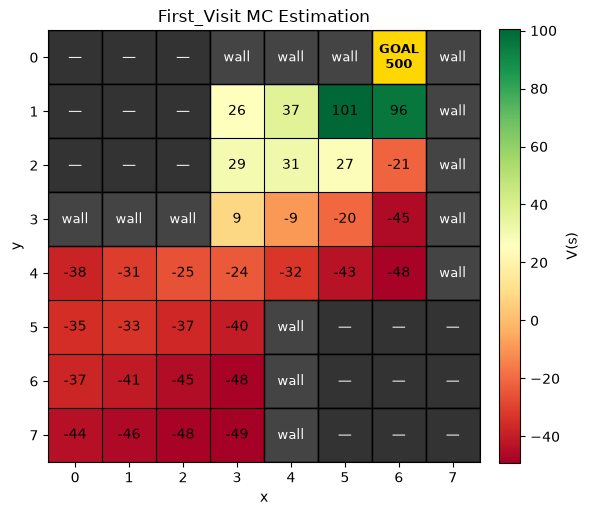

In [4]:
episodes = 100000
gamma = 1

value_functions, iterations = simulate(policy_fn=random_policy, gamma=gamma, n_episodes=episodes)

print(iterations)

plot_value_grid(values=value_functions, rewards=REWARDS, title="First_Visit MC Estimation")

___

### Problem 2. Monte Carlo Control
We'll now turn our attention to control via MC methods. Going forward and for a small parameter $\varepsilon > 0$, recall that an $\varepsilon$-soft policy is any policy $\pi$ satisfying $$\pi\left(a \mid s\right) \geq \frac{\varepsilon}{|\mathcal{A}(s)|}.$$ 


The method that we'll consider is *off-policy MC control* which aims to estimate $\pi_*$. The algorithm uses a behavior policy $b$ to update state-action values via weighted importance sampling. The behavior policy can be anything but needs to provide coverage of the greedy policy, i.e., $b(a \mid s) > 0$ whenever $\pi(a \mid s) > 0$. This property is satisfied for any $\varepsilon$-soft policy, hence we will assume that $b$ is chosen to be soft. The algorithm is restated for convenience:

<div style="color: #fff; background-color: rgb(50, 50, 50);">


<div style="color: #fff; background-color: rgb(10, 10, 10);">

### Off-policy MC Control

</div>
 
**Initialize** for all $s\in \mathcal{S}$, $a \in \mathcal{A(s)}$:
<ul>

$Q(s,a) \in \mathbb{R}$ (arbitrarily)

$C(s,a) \leftarrow 0$

$\pi(s) \leftarrow \text{argmax}_a Q(s,a)$

</ul>

**For each episode:**
<ul>

$b \leftarrow$ any soft policy

Generate an episode using $b \colon S_0, A_0, R_1, S_1, A_1, R_2, \dots, S_{T-1}, A_{T-1}, R_T$

$G \leftarrow 0$
 
$W \leftarrow 1$

Loop for each step of episode, $t = T-1, T-2, \dots, 0$:

<ul>

$G \leftarrow \gamma G + R_{t+1}$

$C(S_t, A_t) \leftarrow C(S_t, A_t) + W$

$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \frac{W}{C(S_t, A_t)} \left(G - Q(S_t, A_t)\right)$

$\pi\left(S_t \right) \leftarrow \text{argmax}_a Q(S_t, a)$

If $A_t \neq \pi\left(S_t\right)$ then exit inner loop (proceed to next episode)

$W \leftarrow \displaystyle \frac{W}{b\left(A_t \mid S_t\right)}$

</ul>
</ul>
</div>

Our tasks are the following:
1. Using $\gamma = 1$, implement the off-policy MC control algorithm. You may make any modifications to the algorithm that you'd like (assuming that they're correct).
2. Perform learning for 10K episodes and evaluate the performance of the deterministic policy $\pi$ every 100th episode (use your policy evaluation algorithm from Lab 2, Problem 3 to get $v_\pi(\text{H0})$). Recall that $b$ can be any soft policy, for example the uniformly random policy, and it may even change between episodes. Present your procedure for the behavioral policy $b$.   
3. Plot evaluation points for (2) as a learning curve averaged over a suitable number of experiments.

### Solution

In [5]:
def _is_valid(r, c):
    """True if (r, c) is inside the grid, not a wall, and has finite reward."""
    return (0 <= r < N_ROWS and 0 <= c < N_COLS
            and not WALLS[r, c] and not np.isnan(REWARDS[r, c]))


def _step(r, c, dr, dc):
    """Deterministic move with wall/out-of-bounds blocking (stays put)."""
    nr, nc = r + dr, c + dc
    if _is_valid(nr, nc):
        return nr, nc
    return r, c + 1


def policy_evaluation(policy, gamma=1, eps=1e-6, max_iters=10000):
    V = np.zeros((N_ROWS, N_COLS))
    V[np.isnan(REWARDS)] = np.nan          # walls → nan
    # terminals already 0 by initialization

    # Collect the list of non-terminal, non-wall states
    states = [(r, c) for r in range(N_ROWS) for c in range(N_COLS)
              if _is_valid(r, c) and not TERMINALS[r, c]]

    for it in range(max_iters):
        delta = 0.0
        V_new = V.copy()
        for (r, c) in states:
            a = policy[(r, c)]
            v = 0.0
            for prob, (dr, dc) in ACTION_OUTCOMES[a]:
                if prob == 0.0:
                    continue
                nr, nc = _step(r, c, dr, dc)
                if TERMINALS[nr, nc]:
                    # reward on entering terminal; V(terminal) = 0
                    v += prob * REWARDS[nr, nc]
                else:
                    v += prob * (REWARDS[nr, nc] + gamma * V[nr, nc])
            V_new[r, c] = v
            delta = max(delta, abs(v - V[r, c]))
        V = V_new
        if delta < eps:
            break

    return V


def simulate_off_policy(policy_fn, gamma=1, n_episodes=10000, evaluation_step=100, seed=42):
    env = GridWorld(seed=seed)
    np.random.seed(seed=seed)
    Q = np.zeros((8, 8, 2), dtype=float)
    C = np.zeros((8, 8, 2), dtype=float)
    pi = np.argmax(Q, axis=2)
    y_values = []
    x_values = []

    for ep in tqdm(range(n_episodes), leave=False):
        hist = run_episode(env, policy_fn)
        G = 0
        W = 1

        for index in range(len(hist) - 1, -1, -1):
            (y, x), action, reward = hist[index]
            G = gamma * G + reward
            C[y, x, action] = C[y, x, action] + W
            Q[y, x, action] = Q[y, x, action] + W/C[y, x, action] * (G - Q[y, x, action])
            if action != pi[y, x]:
                break
            W *= 2      # rho = 1 / (1/2)
        pi = np.argmax(Q, axis=2)

        if ep % evaluation_step == 0:
            value = policy_evaluation(policy=pi, gamma=gamma)[7, 0]
            y_values.append(value)
            x_values.append(ep)
    return pi, (x_values, y_values)


def plot_learning(values, title):

    fig, ax = plt.subplots(1, 1)
    ax.plot(values[0], values[1])
    ax.set_xlabel("episode")
    ax.set_ylabel("value")
    ax.set_title(title)
    plt.show()

100%|██████████| 100/100 [00:59<00:00,  1.69it/s]


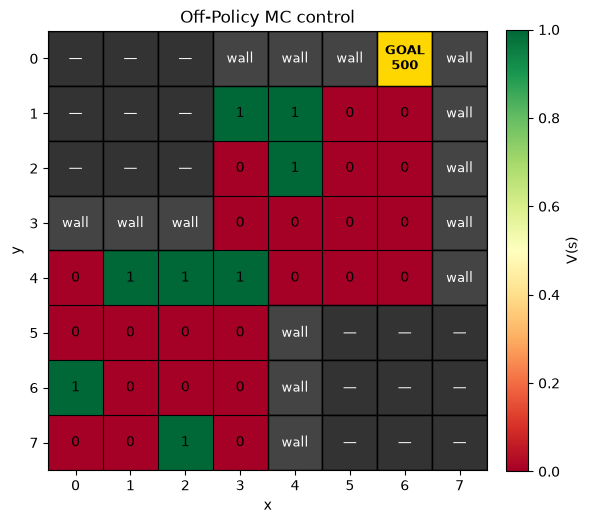

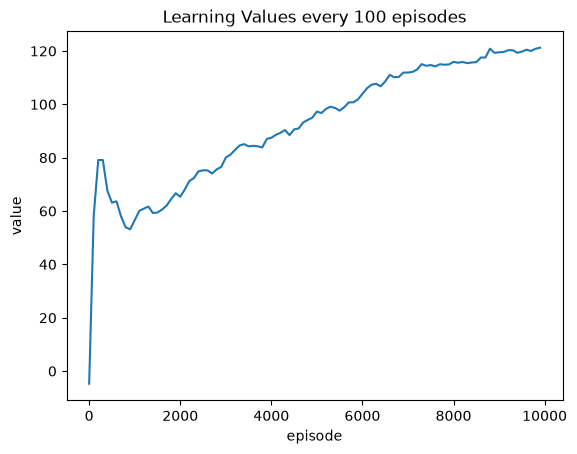

In [6]:
# Actions: 0 = up, 1 = right

gamma = 1
episodes = 10000
step = 100
experiments = 100

simulations = []

for i in tqdm(range(experiments)):
    value_functions, values = simulate_off_policy(policy_fn=random_policy, gamma=gamma, n_episodes=episodes, evaluation_step=step, seed=i)
    simulations.append(values)

simulations = np.array(simulations)
averaged_MC_values = np.mean(simulations, axis=0)

plot_value_grid(values=value_functions, rewards=REWARDS, title="Off-Policy MC control")

plot_learning(values=averaged_MC_values, title=f"Learning Values every {step} episodes")

___

### Problem 3. Q-learning
We'll now move on from MC methods and instead consider an algorithm in temporal-difference control called *Q-learning*. The algorithm aims to estimate an optimal policy $\pi_*$ (Sutton & Barto, chapter 6.5). The main idea is to approximate $q_*$ with a learned function $Q$, where we update $Q$ purely from observed transitions $(S, A, R, S')$. The method is off-policy in the sense that the sampling of transitions is done with any policy derived from $Q$ (often this behavioral policy is taken as the $\varepsilon$-greedy policy w.r.t. $Q$). The algorithm is as follows:

<div style="color: #fff; background-color: rgb(50, 50, 50);">

<div style="color: #fff; background-color: rgb(10, 10, 10);">

### Q-learning

</div>

**Algorithm parameter:** step size $\alpha \in (0, 1]$, small $\varepsilon > 0$
 
**Initialize:**

<ul>

$Q(s,a) \in \mathbb{R}$ for all $s\in \mathcal{S}^+$, $a \in \mathcal{A(s)}$, arbitrarily except that $Q(terminal, \cdot) = 0$

</ul>

**For each episode:**

<ul>

Initialize $S$

Loop for each step of episode:

<ul>

Choose $A$ from $S$ using a policy derived from $Q$ (e.g., $\varepsilon$-greedy)

Take action $A$, observe $R$, $S'$

$Q(S,A) \leftarrow Q(S,A) + \alpha \left(R + \gamma \max_a Q(S', a) - Q(S,A)\right)$

$S \leftarrow S'$

</ul>

until $S$ is terminal

</ul>

</div>

Our tasks are the following:
1. Implement the Q-learning algorithm using $\gamma = 1$ and $\varepsilon$-greedy policies with respect to $Q$ to sample transitions. 
2. Perform learning for 10K episodes and evaluate the greedy policy $\pi := \text{argmax}_a Q(s,a)$ every 100th episode (again you can use your previous evaluation algorithm from Lab 2, Problem 3). Find values for $\alpha$ and $\varepsilon$ that you're satisfied with (w.r.t. the 10K mark). 
3. Present and compare in the same plot average evaluation trajectories for your best method in the previous problem and your best Q-learning method. Thoughts?

### Solution

In [7]:
def eps_greedy(Q, eps):
    if np.random.uniform() < eps:
        return np.random.randint(0, len(Q))
    else:
        return np.argmax(Q)


def simulate_Q_learning(gamma=1, eps=0.1, alphas=None, n_episodes=10000, evaluation_step=100, seed=42, pbar=None):
    env = GridWorld(seed=seed)
    np.random.seed(seed=seed)
    Q = np.zeros((8, 8, 2), dtype=float)
    y_values = []
    x_values = []

    for ep in range(n_episodes):

        env.reset()
        terminated = False
        while not terminated:
            (y, x) = env.state
            A = eps_greedy(Q[y, x], eps=eps)
            (ny, nx), R, terminated = env.step(action=A)

            Q[y, x, A] += alpha * (R + gamma * np.max(Q[ny, nx]) - Q[y, x, A])

        pi = np.argmax(Q, axis=2)

        if ep % evaluation_step == 0:
            value = policy_evaluation(policy=pi, gamma=gamma)[7, 0]
            y_values.append(value)
            x_values.append(ep)

    pbar.update(n_episodes)
    return pi, (x_values, y_values)

100%|██████████| 1600000/1600000 [02:31<00:00, 10533.34it/s]

Best: 
	Epsilon: 0.2, Alpha: 0.1


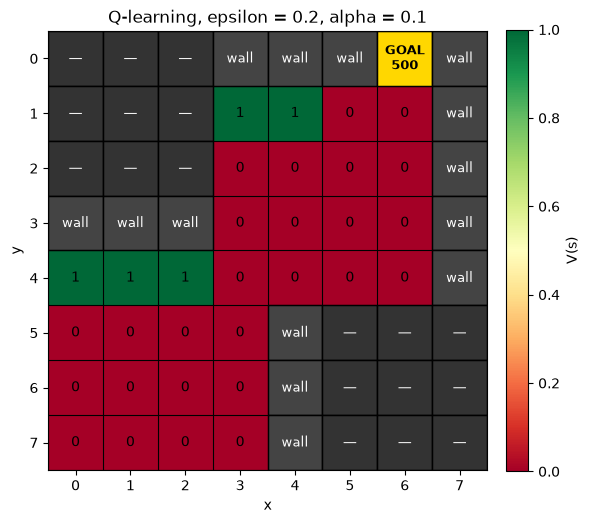

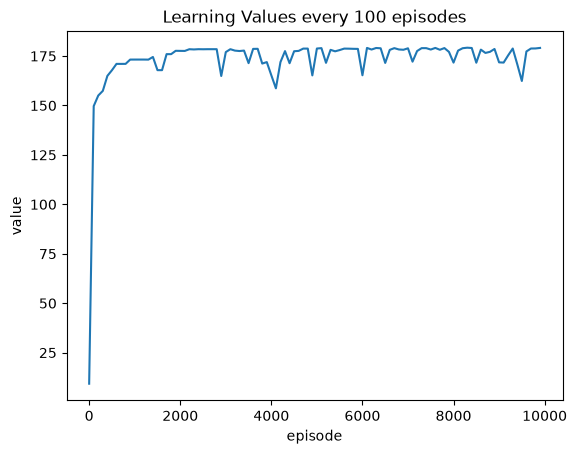

In [8]:
# Actions: 0 = up, 1 = right

gamma = 1
epsilons = [0.1, 0.2, 0.5, 0.9]
alphas = [0.1, 0.2, 0.5, 0.1]
experiments = 10
episodes = 10000
step = 100

simulations = np.zeros((experiments, len(epsilons), len(alphas), 2, episodes//step))
pis = []

seed = 0

pbar = tqdm(total=(len(epsilons) * len(alphas) * experiments * episodes))

for j, eps in enumerate(epsilons):
    for k, alpha in enumerate(alphas):
        for i in range(experiments):
            policy, values = simulate_Q_learning(gamma=gamma, eps=eps, alphas=alpha, n_episodes=episodes, evaluation_step=step, seed=seed, pbar=pbar)
            simulations[i, j, k] = values
            pis.append(policy)
            seed += 1

pbar.close()
averaged_Q_values = np.mean(simulations, axis=0)
final_y_scores = averaged_Q_values[:, :, 1, -1]
final_index = np.argmax(final_y_scores)

epsilon_idx, alpha_idx = np.unravel_index(final_index, final_y_scores.shape)

print(f"Best: \n\tEpsilon: {epsilons[epsilon_idx]}, Alpha: {alphas[alpha_idx]}")

plot_value_grid(values=pis[final_index], rewards=REWARDS, title=f"Q-learning, epsilon = {epsilons[epsilon_idx]}, alpha = {alphas[alpha_idx]}")

plot_learning(values=averaged_Q_values[epsilon_idx, alpha_idx, :, :], title=f"Learning Values every {step} episodes")

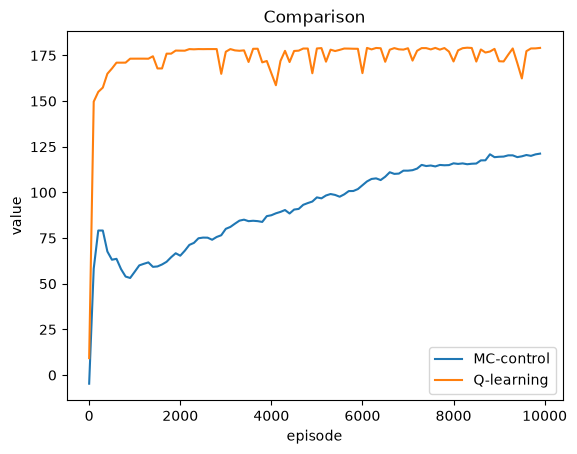

In [9]:
fig, ax = plt.subplots(1, 1)
ax.plot(averaged_MC_values[0], averaged_MC_values[1], label="MC-control")
ax.plot(averaged_Q_values[epsilon_idx, alpha_idx, 0, :], averaged_Q_values[epsilon_idx, alpha_idx, 1, :], label="Q-learning")
ax.set_xlabel("episode")
ax.set_ylabel("value")
ax.set_title("Comparison")
ax.legend()
plt.show()

___

# Part B - Dyna Maze

In this section we'll study a planning algorithm called *Dyna-Q* and use it in a dyna maze environment similar, but slightly more complex, to the one found in Example 8.1 in the course literature (Sutton & Barto, Chapter 8.2). 

<div>

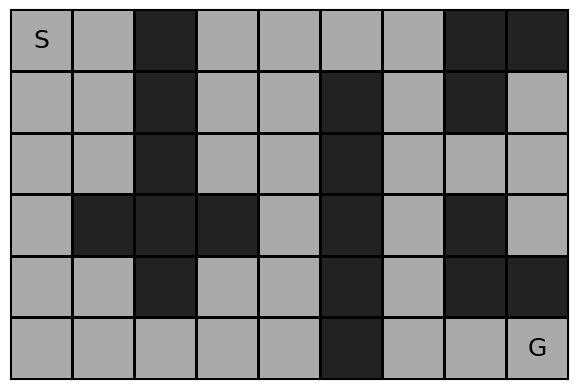

</div>

The task for the agent is to find its way out of the maze by moving from square `S` to square `G` using one of four actions: `UP`, `RIGHT`, `DOWN` and `LEFT`. The edge of the map and the black squares are obstacles, and all transitions are deterministic. When the agent reaches `G` it gets returned to square `S` and the episode is reset. 


___

### Problem 4. Dyna-Q

The Dyna-Q algorithm extends Q-learning by also using a model $Model(S,A)$ for simulated experience of the environment. The model starts out with blank state containing no information about the environment. As transitions are observed the model gets updated. Planning is then done in each algorithmic step by sampling transitions from the model and applying Q-learning updates on the simulated experience for a total of $n$ planning steps. Formally we can state the method by:

<div style="color: #fff; background-color: rgb(50, 50, 50);">

<div style="color: #fff; background-color: rgb(10, 10, 10);">

### Tabular Dyna-Q ($n$ planning steps)

</div>
 
Initialize $Q(s,a)$ and $Model(s,a)$ for all $s \in \mathcal{S}$ and $a \in \mathcal{A}$

Loop forever:

<ul>

(a) $S \leftarrow$ current (nonterminal) state 

(b) $A \leftarrow$ $\varepsilon$-greedy $(S,Q)$

(c) Take action $A$; observe resultant reward $R$ and state $S'$

(d) $Q(S,A) \leftarrow Q(S,A) + \alpha \left(R + \gamma \max_a Q(S', a) - Q(S,A)\right)$

(e) $Model(S,A) \leftarrow R, S'$ (assuming deterministic environment)

(f) Loop repeat $n$ times:

<ul>

$S \leftarrow$ random previously observed state

$A \leftarrow$ random action previously taken in $S$

$R, S' \leftarrow Model(S,A)$

$Q(S,A) \leftarrow Q(S,A) + \alpha \left(R + \gamma \max_a Q(S', a) - Q(S,A)\right)$

</ul>
</ul>
</div>


We'll now repeat the experiments done by Sutton & Barto but in this new environment. Our tasks are the following (using $\gamma = 0.95$, $\varepsilon = 0.1$, $\alpha = 0.1$):
1. Feel free to use any suitable reward model for this task and create an environment for the maze.   
2. Create a model class with the functionality of adding new observed transitions and the ability to uniformly sample from observed data. **Hint:** Since the environment is deterministic we could try something similar to the outline in following code.
    <div > 

    ```Python
    class Model:

        def __init__(self):
            """ Initialize empty data """
            raise NotImplementedError

        def add(self, state, action, reward, next_state):
            """ Adds an observed transition (S,A,R,S') to the data """
            raise NotImplementedError

        def sample(self):
            """ Uniformly samples a transition (S,A,R,S') from observed data """
            raise NotImplementedError
    ```

    </div>
3. Using the experimental settings from Example 8.1, try to solve the task with Q-learning (essentially Dyna-Q with $n = 0$). That is, perform learning for a maximum of 50 episodes, and for each episode store the number of steps taken by the agent before the `G` state is reach. Repeat the experiment 30 times and estimate the average number of steps taken for each episode. You should see a clear learning progression, where the number of steps needed gets less and less for each episode (on average). 
4. Repeat (3) but now with Dyna-Q and $n = 5$.
5. Repeat (3) but now with Dyna-Q and $n = 50$. 
6. Similar to Figure 8.2 in Sutton & Barto, visualize learning progression for all three algorithms in a single plot showing the average number of steps needed to reach `G` (up to the 50th episode). Conclusions?

### Solution

In [10]:
REWARDS = np.ones((6, 9)) * -1
REWARDS[-1, -1] = 1     # Mål

WALLS = np.zeros((6, 9), dtype=bool)
WALLS[0:4, 2] = True
WALLS[3, 1:3] = True
WALLS[1:6, 5] = True
WALLS[(0, 0, 1, 3, 4, 4), (7, 8, 7, 7, 7, 8)] = True

TERMINALS = (REWARDS != -1)

# idx: [(p, (y, x))]
ACTION_OUTCOMES = {
    0: [(1.0, (-1, 0))],  # UP
    1: [(1.0, (0, 1))],  # RIGHT
    2: [(1.0, (1, 0))],  # DOWN
    3: [(1.0, (0, -1))],  # LEFT
}

N_ROWS, N_COLS = REWARDS.shape
N_ACTIONS = len(ACTION_OUTCOMES)


class GridWorld:
    def __init__(self, start=(0, 0), seed=None):
        """Creates and initializes the environment."""
        self.start = start
        self.rewards = REWARDS.copy()
        self.walls = WALLS.copy()
        self.terminals = TERMINALS.copy()
        self.H, self.W = self.rewards.shape
        self.rng = np.random.default_rng(seed)
        self.state = self.start
        self.terminated = False


    def viable(self, action):
        """Controlls if the planned step is viable"""
        y, x = self.state
        (dy, dx) = ACTION_OUTCOMES[action][0][1]
        ny, nx = y + dy, x + dx

        viable_move = False
        if (0 <= ny < N_ROWS) and (0 <= nx < N_COLS):
            if not WALLS[ny, nx]:
                viable_move = True

        return viable_move


    def reset(self):
        """Resets the environment for a new episode."""
        self.state = self.start
        self.terminated = False
        return self.state


    def observe(self):
        """Retrieves the current state."""
        return self.state


    def step(self, action):
        """The dynamic step function.
        Returns -> next_state: (y, x), reward: float, terminated: bool
        """
        if self.terminated:
            # Already terminal; no-op
            return self.state, 0.0, True

        y, x = self.state
        outcomes = ACTION_OUTCOMES[action]
        probs = [p for p, _ in outcomes]
        idx = self.rng.choice(len(outcomes), p=probs)
        _, (dy, dx) = outcomes[idx]

        ny, nx = y + dy, x + dx

        if not self.viable(action): # Treat an invalid move as a NO-OP
            ny, nx = y, x

        # Reward for entering (ny, nx)
        reward = float(self.rewards[ny, nx])
        # Termination: entering a terminal cell
        terminated = bool(self.terminals[ny, nx])

        self.state = (ny, nx)
        self.terminated = terminated
        return (ny, nx), reward, terminated


class Model:
    def __init__(self, seed=None):
        self.transitions = []
        self.rng = np.random.default_rng(seed)

    def add(self, state, action, reward, next_state):
        '''Add an observed transition'''
        self.transitions.append((state, action, reward, next_state))

    def sample(self):
        '''Sample a previously observed transition'''
        choice = self.rng.integers(0, len(self.transitions))
        return self.transitions[choice]

In [11]:
def simulate_dyna_Q(gamma=1, eps=0.1, alpha=1, n=5, n_episodes=100, seed=42, pbar=None):
    env = GridWorld(seed=seed)
    model = Model(seed=seed)
    Q = np.zeros((N_ROWS, N_COLS, N_ACTIONS))
    total_steps = np.zeros((n_episodes), dtype=float)

    for ep in range(n_episodes):
        env.reset()
        (y, x) = env.observe()
        terminated = env.terminated
        steps = 0

        while not terminated:
            A = eps_greedy(Q[y, x], eps=eps)    # Allow moves into walls as NO-OP

            (ny, nx), R, terminated = env.step(action=A)

            Q[y, x, A] += alpha * (R + gamma * np.max(Q[ny, nx]) - Q[y, x, A])
            model.add((y, x), A, R, (ny, nx))
            y, x = ny, nx

            steps += 1

            for _ in range(n):
                (y0, x0), A0, R0, (y1, x1) = model.sample()
                Q[y0, x0, A0] += alpha * (R0 + gamma * np.max(Q[y1, x1]) - Q[y0, x0, A0])

        total_steps[ep] = steps
        pbar.update()
    
    return total_steps


def plot_dyna_Q_steps(steps, title):
    episode = np.arange(1, steps.shape[0] + 1)

    fig, ax = plt.subplots(1, 1)
    ax.plot(episode, steps)
    ax.set_xlabel("episode")
    ax.set_ylabel("average steps")
    ax.set_title(title)
    plt.show()


100%|██████████| 1500/1500 [00:03<00:00, 405.45it/s]


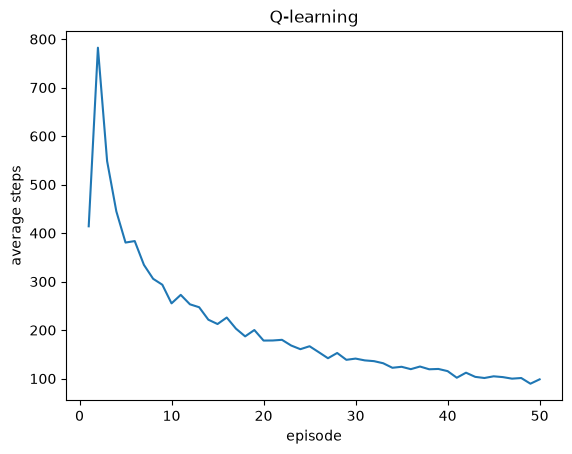

In [12]:
episodes = 50
gamma = 0.95
epsilon = 0.1
alpha = 0.1
experiments = 30
n = 0

simulations = np.zeros((experiments, episodes), dtype=float)
pbar = tqdm(total=episodes * experiments)

for i in range(experiments):
    steps = simulate_dyna_Q(gamma=gamma, eps=epsilon, alpha=alpha, n=n, n_episodes=episodes, seed=i, pbar=pbar)
    simulations[i] = steps

pbar.close()

average_steps_0 = np.mean(simulations, axis=0)

plot_dyna_Q_steps(steps=average_steps_0, title="Q-learning")

100%|██████████| 1500/1500 [00:03<00:00, 469.47it/s]


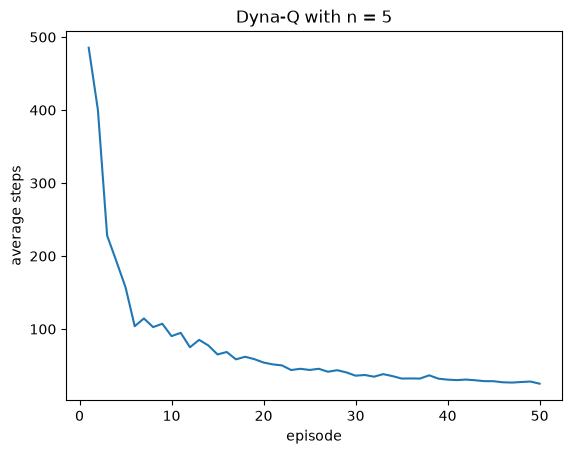

In [13]:
episodes = 50
gamma = 0.95
epsilon = 0.1
alpha = 0.1
experiments = 30
n = 5

simulations = np.zeros((experiments, episodes), dtype=float)
pbar = tqdm(total=episodes * experiments)

for i in range(experiments):
    steps = simulate_dyna_Q(gamma=gamma, eps=epsilon, alpha=alpha, n=n, n_episodes=episodes, seed=i, pbar=pbar)
    simulations[i] = steps

pbar.close()

average_steps_5 = np.mean(simulations, axis=0)

plot_dyna_Q_steps(steps=average_steps_5, title=f"Dyna-Q with n = {n}")

100%|██████████| 1500/1500 [00:09<00:00, 160.12it/s]


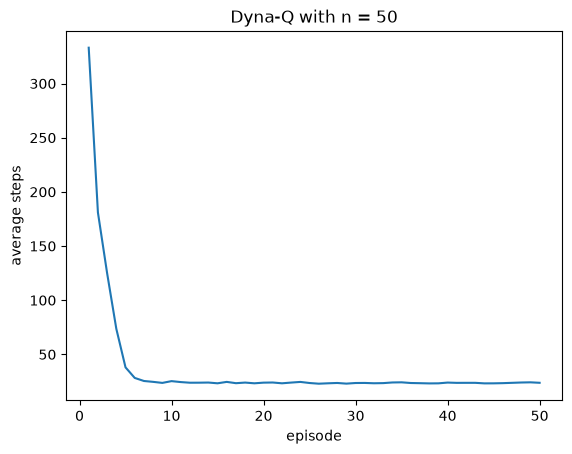

In [14]:
episodes = 50
gamma = 0.95
epsilon = 0.1
alpha = 0.1
experiments = 30
n = 50

simulations = np.zeros((experiments, episodes), dtype=float)
pbar = tqdm(total=episodes * experiments)

for i in range(experiments):
    steps = simulate_dyna_Q(gamma=gamma, eps=epsilon, alpha=alpha, n=n, n_episodes=episodes, seed=i, pbar=pbar)
    simulations[i] = steps

pbar.close()

average_steps_50 = np.mean(simulations, axis=0)

plot_dyna_Q_steps(steps=average_steps_50, title=f"Dyna-Q with n = {n}")

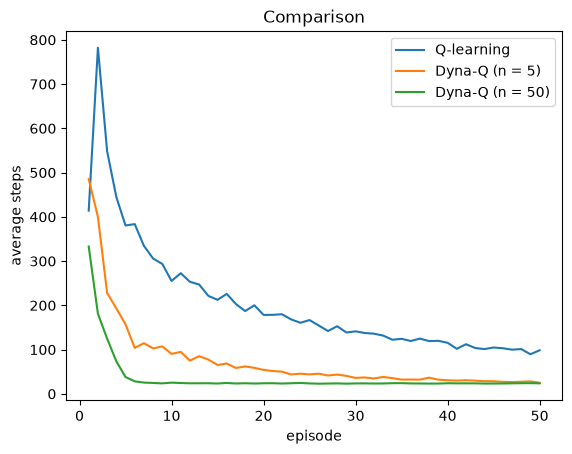

In [15]:
def plot_mult_dyna_Q(steps_mult, labels, title):
    episode = np.arange(1, steps.shape[0] + 1)

    fig, ax = plt.subplots(1, 1)
    for i, label in enumerate(labels):
        ax.plot(episode, steps_mult[i], label=label)
    ax.set_xlabel("episode")
    ax.set_ylabel("average steps")
    ax.set_title(title)
    ax.legend()
    plt.show()


all_steps = np.array([average_steps_0, average_steps_5, average_steps_50])

labels = ["Q-learning", "Dyna-Q (n = 5)", "Dyna-Q (n = 50)"]

plot_mult_dyna_Q(all_steps, labels, title="Comparison")

___

# Part C - Game of Sim

In this final section we'll study a two-player Ramsey game called *Sim*, where our aim is to try to beat our fixed opponent using tabular reinforcement learning. 


### Sim
The playing arena for Sim is $K_6$, the complete graph of six vertices. 

<div>

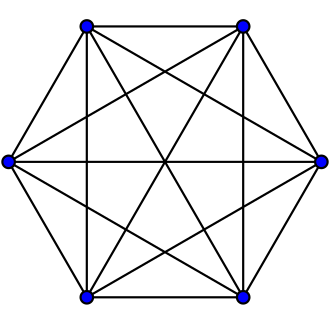

</div>

The two players, let's call them `Red`and `Blue`, take turns in coloring uncolored edges of the graph with their respective colors, with `Red` starting first. The first player that manages to make a triangle solely made of their color loses the game. So the goal for each player is to pick edges without creating a 3-cycle in their respective mono-colored subgraph. 

___

### Problem 5. Beating the Red Player

In this final problem and the culmination of our hard work, we'll try to use what we have learned in the course in order to device a policy that beats an opponent to a sufficient degree. We'll assume that our agent always starts as `Blue` and our `Red` opponent is either:
* The *Scrooge McDuck* player that, if possible, greedily chooses the first indexed action that does not create a triangle. Otherwise it chooses any losing action.  
* The *Simian Sage* player that, if possible, chooses uniformly at random among the actions that do not create a triangle. Otherwise it chooses any losing action.

Our tasks are the following:
1. Implement all that you need and solve the problem of beating *Scrooge Mcduck* in 100 games out of 100 (on average) using tabular reinforcement learning. In particular you're free to experiment with and choose any method in Part I of the course literature and any reward model that you fancy.  
2. Implement all that you need and solve the problem of beating the *Simian Sage* in at least 95 games out of 100 (on average) using tabular reinforcement learning. In particular you're free to experiment with and choose any method in Part I of the course literature and any reward model that you fancy. 
3. Store the learning progression of your method by periodic evaluation points (where in each such point you evaluate your current greedy policy for 100 games against `Red` and record the win frequency). Average these learning trajectories over a suitable number of experiments and present curves for the average win frequency at each evaluation point.

**Hint**: Unabstracted this environment may be the largest environment that we've considered so far. Note that the entire state-action space does not need to be precomputed if your functions are implemented by maps (dictionaries) and only add new keys when first observed (however this may not be the most efficient solution for computations). Moreover, since the game displays symmetry, there are many options for great compression of the state-action space. Even if we don't take the path of a fully isomorphic treatment, there are some simple but obvious examples: Why can we assume that `Red` always chooses a specific edge at the start of the game? Does the order matter in how the previous edges were selected?

### Solution

In [16]:
import numpy as np
import random
import itertools


NUM_VERTICES = 6


class GameOfSim:
    def __init__(self, opponent_ai='scrooge', seed=None, verbose=False):
        """
        Initializes the Game of Sim.
        :param opponent_ai: 'scrooge' or 'simian_sage'
        """

        self.num_vertices = NUM_VERTICES
        self.verbose = verbose
        random.seed(seed)

        # State representation:
        # 0 = Uncolored, 1 = BLUE (Player), 2 = RED (Opponent)
        # We use a 6x6 adjacency matrix. The matrix is symmetric.
        self.state = np.zeros((self.num_vertices, self.num_vertices), dtype=int)

        # Define all possible edges (pairs of vertices)
        self.all_edges = []
        for i in range(self.num_vertices):
            for j in range(i + 1, self.num_vertices):
                self.all_edges.append((i, j))

        self.opponent_ai = opponent_ai
        self.terminated = False
        self.winner = None

        # Precompute triangles (sets of 3 edges that form a triangle)
        self.triangles = []
        for combo in itertools.combinations(range(self.num_vertices), 3):
            u, v, w = combo
            self.triangles.append([(u, v), (v, w), (u, w)])

    def _get_edge_value(self, u, v):
        """Helper to get the value of an edge regardless of order."""
        return self.state[u, v]

    def _set_edge(self, u, v, player):
        """Sets the edge for the player and updates the matrix."""
        self.state[u, v] = player
        self.state[v, u] = player

    def _has_triangle(self, player):
        """
        Checks if the specified player has formed a triangle.
        """
        # Create a boolean mask where True means the edge belongs to 'player'
        # We use simple equality comparison
        mask = (self.state == player)

        # Check all triangles
        for tri in self.triangles:
            # If all three edges in the triangle are True in the mask
            e1, e2, e3 = tri
            if mask[e1[0], e1[1]] and mask[e2[0], e2[1]] and mask[e3[0], e3[1]]:
                return True
        return False

    def _get_available_moves(self, player):
        """Returns a list of tuples (u, v) for all uncolored edges."""
        available = []
        for u, v in self.all_edges:
            if self.state[u, v] == 0:
                available.append((u, v))
            else:
                available.append(None)

        if player == 2:
            temp = []
            for edge in available:
                if edge is not None:
                    temp.append(edge)
            available = temp

        return available

    def _get_available_index_moves(self):
        """Returns a list of tuples (u, v) for all uncolored edges."""
        available = []
        for i, (u, v) in enumerate(self.all_edges):
            if self.state[u, v] == 0:
                available.append(i)
        return available

    def _get_state(self):
        """Helper function for the model."""
        edges = []
        for u, v in self.all_edges:
            edges.append(self.state[u, v])
        return edges

    def _would_create_triangle(self, u, v, player):
        """
        Checks if coloring edge (u,v) would create a triangle for 'player'.
        Used for AI decision making.
        """
        # Temporarily set the edge
        self._set_edge(u, v, player)
        # Check for triangle
        created = self._has_triangle(player)
        # Undo the move
        self._set_edge(u, v, 0)
        return created

    def _scrooge_move(self):
        """
        Scrooge McDuck Strategy:
        1. Greedily chooses the first indexed action that does not create a triangle.
        2. Otherwise chooses any losing action (any available move).
        """
        available = self._get_available_moves(2)

        for move in available:
            if not self._would_create_triangle(move[0], move[1], 2): # 2 is RED
                return move

        # If all moves create a triangle, we have lost anyway, pick the first.
        return available[0]

    def _simian_move(self):
        """
        Simian Sage Strategy:
        1. Uniformly random among actions that do not create a triangle.
        2. Otherwise chooses any losing action.
        """
        available = self._get_available_moves(2)

        safe_moves = []
        for move in available:
            if not self._would_create_triangle(move[0], move[1], 2): # 2 is RED
                safe_moves.append(move)

        if safe_moves:
            return random.choice(safe_moves)
        else:
            # All moves are losing, pick randomly (or first) from available
            return random.choice(available)

    def _opponent_turn(self):
        """Executes the opponent's turn based on initialized AI."""
        if self.opponent_ai == 'scrooge':
            move = self._scrooge_move()
        else:
            move = self._simian_move()

        u, v = move
        self._set_edge(u, v, 2) # 2 is RED
        if self.verbose:
            print(f"RED (Opponent) chose: {u}-{v}")

        if self._has_triangle(2):
            # Opponent formed triangle, User wins
            self.terminated = True
            self.winner = 1

        return self.terminated, self._compute_reward()

    def _player_turn(self, action):
        u, v = self._get_available_moves(1)[action]
        self._set_edge(u, v, 1)
        if self.verbose:
            print(f"BLUE (Player) chose: {u}-{v}")

        if self._has_triangle(1):
            # Player formed triangle, AI wins
            self.terminated = True
            self.winner = 2

        return self.terminated, self._compute_reward()

    def _compute_reward(self):
        """Rewards the model if it wins,  punishes otherwise."""
        reward = 0
        if self.winner == 1:
            reward = 1
        elif self.winner == 2:
            reward = -1
        return reward


class Model:
    def __init__(self, seed=None):
        self.transitions = []
        self.rng = np.random.default_rng(seed)

    def add(self, state, action, reward, next_state, terminated):
        '''Add an observed transition'''
        self.transitions.append((state, action, reward, next_state, terminated))

    def sample(self):
        '''Sample a previously observed transition'''
        choice = self.rng.integers(0, len(self.transitions))
        return self.transitions[choice]


"-------------------------------------------------------------------------------"


class QTable:
    def __init__(self, n_actions=16, default=0.0):
        self.n_actions = n_actions
        self.default = default
        self._table = {}

    def get(self, state):
        return self._table.get(state)

    def get_or_init(self, state):
        arr = self._table.get(state)
        if arr is None:
            arr = np.full(self.n_actions, self.default, dtype=float)
            self._table[state] = arr
        return arr

    def __len__(self):
        return len(self._table)


def eps_greedy_sim(Q, state, available_moves, eps, episode):
    limit = eps(episode)
    if np.random.uniform() < limit:
        return random.choice(available_moves)
    q_s = Q.get_or_init(state)
    masked = np.full(len(q_s), -np.inf)
    masked[available_moves] = q_s[available_moves]
    return int(np.argmax(masked))


def simulate_dyna_Q_sim(AI='scrooge', gamma=1, eps=lambda x: 0.1, alpha=1, n=5, n_episodes=100, seed=42, pbar=None):
    model = Model(seed=seed)
    Q = QTable(n_actions=16)

    total_wins = np.zeros((n_episodes), dtype=float)

    def update_Q(state, action, reward, next_state, terminated):
        q_s = Q.get_or_init(state)
        if terminated:
            td_target = reward
        else:
            q_ns = Q.get_or_init(next_state)
            td_target = reward + gamma * np.max(q_ns)
        q_s[action] += alpha * (td_target - q_s[action])

    for ep in range(n_episodes):
        env = GameOfSim(opponent_ai=AI, seed=ep)
        terminated = env.terminated
        wins = 0
        current_turn = 2

        while not terminated:
            
            # Opponent playing
            if current_turn == 2:
                S = tuple(env._get_state()) + (2,)
                terminated, R = env._opponent_turn()
                NS = tuple(env._get_state()) + (1,)
                update_Q(S, 15, R, NS, terminated)  # Update Q with a NOOP since the Opponent played
                model.add(S, 15, R, NS, terminated)
                current_turn = 1

            # "Player" playing
            else:
                S = tuple(env._get_state()) + (1,)
                A = eps_greedy_sim(Q, S, available_moves=env._get_available_index_moves(), eps=eps, episode=ep)
                terminated, R = env._player_turn(action=A)
                NS = tuple(env._get_state()) + (2,)
                update_Q(S, A, R, NS, terminated)
                model.add(S, A, R, NS, terminated)
                current_turn = 2

                for _ in range(n):
                    S, A, R, NS, term = model.sample()
                    update_Q(S, A, R, NS, term)

        if env.winner == 1:
            wins += 1

        total_wins[ep] = wins
        if pbar is not None:
            pbar.update(1)
    
    return total_wins


def evaluate(agent_Q, AI, n_games=200, seed=0):
    rng = np.random.default_rng(seed)
    wins = 0
    for g in range(n_games):
        env = GameOfSim(opponent_ai=AI, seed=seed * 10_000 + g)
        while not env.terminated:
            env._opponent_turn()
            if env.terminated:
                break
            S = tuple(env._get_state()) + (1,)
            avail = env._get_available_index_moves()
            q_s = agent_Q.get_or_init(S)
            masked = np.full(len(q_s), -np.inf)
            masked[avail] = q_s[avail]
            A = int(np.argmax(masked))
            env._player_turn(A)
        if env.winner == 1:
            wins += 1
    return wins / n_games

___

100%|██████████| 2000/2000 [00:01<00:00, 1067.77it/s]


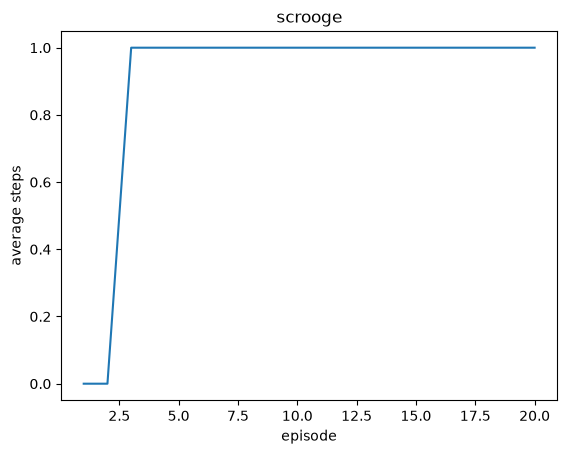

In [17]:
episodes    = 20
gamma       = 1
epsilon     = lambda x: 1e-5
alpha       = 1
experiments = 100
n           = 30
opponent    = "scrooge"

simulations = np.zeros((experiments, episodes), dtype=float)
pbar = tqdm(total=episodes * experiments)

for i in range(experiments):
    sims = simulate_dyna_Q_sim(
        AI=opponent,
        gamma=gamma,
        eps=epsilon,
        alpha=alpha,
        n=n,
        n_episodes=episodes,
        seed=episodes * i,
        pbar=pbar,
    )
    simulations[i] = sims

pbar.close()

average_moves = np.mean(simulations, axis=0)

plot_dyna_Q_steps(steps=average_moves, title=opponent)

100%|██████████| 10000/10000 [00:07<00:00, 1393.86it/s]


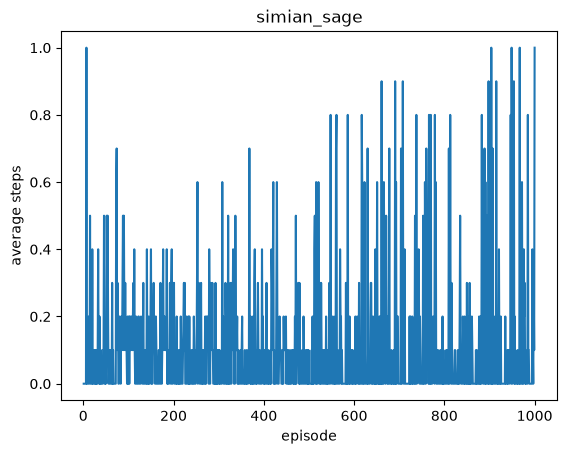

In [18]:
episodes    = 1000
gamma       = 1
epsilon     = lambda x: 0.995 ** x
alpha       = 0.2
experiments = 10
n           = 20
opponent    = "simian_sage"

simulations = np.zeros((experiments, episodes), dtype=float)
pbar = tqdm(total=episodes * experiments)

for i in range(experiments):
    sims = simulate_dyna_Q_sim(
        AI=opponent,
        gamma=gamma,
        eps=epsilon,
        alpha=alpha,
        n=n,
        n_episodes=episodes,
        seed=episodes * i,
        pbar=pbar,
    )
    simulations[i] = sims

pbar.close()

average_moves = np.mean(simulations, axis=0)

plot_dyna_Q_steps(steps=average_moves, title=opponent)

### AI generated version

In [19]:
NUM_VERTICES = 6


class GameOfSim:
    def __init__(self, opponent_ai='scrooge', seed=None, verbose=False):
        self.num_vertices = NUM_VERTICES
        self.verbose = verbose
        self.rng = random.Random(seed)           # FIX: per-instance RNG, not global

        # 0 = uncolored, 1 = BLUE (player/learner), 2 = RED (opponent)
        self.state = np.zeros((self.num_vertices, self.num_vertices), dtype=int)

        self.all_edges = []
        for i in range(self.num_vertices):
            for j in range(i + 1, self.num_vertices):
                self.all_edges.append((i, j))

        self.opponent_ai = opponent_ai
        self.terminated = False
        self.winner = None

        self.triangles = []
        for combo in itertools.combinations(range(self.num_vertices), 3):
            u, v, w = combo
            self.triangles.append([(u, v), (v, w), (u, w)])

    # ---------- low-level helpers ----------
    def _set_edge(self, u, v, player):
        self.state[u, v] = player
        self.state[v, u] = player

    def _has_triangle(self, player):
        mask = (self.state == player)
        for e1, e2, e3 in self.triangles:
            if mask[e1[0], e1[1]] and mask[e2[0], e2[1]] and mask[e3[0], e3[1]]:
                return True
        return False

    def _get_available_moves(self):
        """List of (u, v) for uncolored edges, in all_edges order."""
        return [(u, v) for (u, v) in self.all_edges if self.state[u, v] == 0]

    def _get_available_index_moves(self):
        """List of integer indices into all_edges for uncolored edges."""
        return [i for i, (u, v) in enumerate(self.all_edges) if self.state[u, v] == 0]

    def _get_state(self):
        """Length-15 list of edge colours in all_edges order."""
        return [self.state[u, v] for (u, v) in self.all_edges]

    def _would_create_triangle(self, u, v, player):
        self._set_edge(u, v, player)
        created = self._has_triangle(player)
        self._set_edge(u, v, 0)
        return created

    # ---------- opponent policies ----------
    def _scrooge_move(self):
        available = self._get_available_moves()
        for move in available:
            if not self._would_create_triangle(move[0], move[1], 2):
                return move
        return available[0]

    def _simian_move(self):
        available = self._get_available_moves()
        safe = [m for m in available if not self._would_create_triangle(m[0], m[1], 2)]
        return self.rng.choice(safe) if safe else self.rng.choice(available)

    # ---------- turns ----------
    def _opponent_turn(self):
        move = self._scrooge_move() if self.opponent_ai == 'scrooge' else self._simian_move()
        u, v = move
        self._set_edge(u, v, 2)
        if self.verbose:
            print(f"RED (Opponent) chose: {u}-{v}")

        if self._has_triangle(2):
            self.terminated = True
            self.winner = 1          # opponent lost, player won
        return self.terminated, self._compute_reward()

    def _player_turn(self, edge_index):
        u, v = self.all_edges[edge_index]
        self._set_edge(u, v, 1)
        if self.verbose:
            print(f"BLUE (Player) chose: {u}-{v}")
        if self._has_triangle(1):
            self.terminated = True
            self.winner = 2
        return self.terminated, self._compute_reward()

    def _compute_reward(self):
        if self.winner == 1:
            return 1.0
        if self.winner == 2:
            return -1.0
        return 0.0


class Model:
    def __init__(self, seed=None):
        self.transitions = []
        self.rng = np.random.default_rng(seed)

    def add(self, state, action, reward, next_state, terminated):
        self.transitions.append((state, action, reward, next_state, terminated))

    def __len__(self):
        return len(self.transitions)

    def sample(self):
        i = int(self.rng.integers(0, len(self.transitions)))
        return self.transitions[i]


class QTable:
    def __init__(self, n_actions=15, default=0.0):
        # FIX: 15 actions, one per edge (no NOOP slot)
        self.n_actions = n_actions
        self.default = default
        self._table = {}

    def get(self, state):
        return self._table.get(state)

    def get_or_init(self, state):
        arr = self._table.get(state)
        if arr is None:
            arr = np.full(self.n_actions, self.default, dtype=float)
            self._table[state] = arr
        return arr

    def __len__(self):
        return len(self._table)


def eps_greedy_sim(Q, state, available_moves, eps, rng):
    if rng.random() < eps:
        return rng.choice(available_moves)
    q_s = Q.get_or_init(state)
    masked = np.full(len(q_s), -np.inf)
    masked[available_moves] = q_s[available_moves]
    return int(np.argmax(masked))

In [20]:
def simulate_dyna_Q_sim(AI='scrooge', gamma=1.0, eps=0.1, alpha=0.1,
                        n=5, n_episodes=100, seed=42, pbar=None):
    """
    Dyna-Q where the player (BLUE) is the learner.
    Actions are edge indices into env.all_edges (0..14).
    Opponent (RED) moves are part of the environment, not modelled in Q.
    """
    model = Model(seed=seed)
    Q = QTable(n_actions=15)            # FIX: 15 actions, no NOOP

    rng = np.random.default_rng(seed)
    wins = np.zeros(n_episodes, dtype=float)

    def update_q(state, action, reward, next_state, terminated):
        q_s = Q.get_or_init(state)
        if terminated:
            td_target = reward
        else:
            q_ns = Q.get_or_init(next_state)
            td_target = reward + gamma * float(np.max(q_ns))
        q_s[action] += alpha * (td_target - q_s[action])

    for ep in range(n_episodes):
        env = GameOfSim(opponent_ai=AI, seed=seed * 10_000 + ep)
        pending = None

        # The game alternates RED (opponent) and BLUE (player), starting with RED.
        # We track the player's *last* decision so that, when the opponent
        # terminates the game by forming a triangle, we can credit the +1
        # terminal reward to that winning move.
        while not env.terminated:
            # ---- RED (opponent) moves: this is environment dynamics ----
            env._opponent_turn()
            if env.terminated:
                # Opponent lost => the player's last move was winning.
                # FIX: credit +1 to the player's last (S, A) with terminated=True,
                #      and store it in the model with terminated=True so replay
                #      preserves the value rather than overwriting it with a
                #      bootstrapped estimate.
                if pending is not None:
                    S_p, A_p, NS_p = pending
                    update_q(S_p, A_p, +1.0, NS_p, terminated=True)
                    model.add(S_p, A_p, +1.0, NS_p, True)
                break

            # ---- BLUE (player) moves: this is the learned decision ----
            S = tuple(env._get_state()) + (1,)      # (state, "it's my turn")
            avail = env._get_available_index_moves()
            A = eps_greedy_sim(Q, S, avail, eps, rng)
            terminated, R = env._player_turn(A)     # R = -1 if we just lost, else 0
            NS = tuple(env._get_state()) + (2,)     # (state, "opponent's turn")

            update_q(S, A, R, NS, terminated)
            model.add(S, A, R, NS, terminated)

            # after update_q / model.add for this player move, and BEFORE the
            # possible break for termination, record the pending tuple:
            pending = (S, A, NS)

            if terminated:
                break

            # Dyna-Q replay
            if len(model) > 0:
                for _ in range(n):
                    s_s, a_a, r_r, s_ns, term = model.sample()
                    update_q(s_s, a_a, r_r, s_ns, term)

            pending = (S, A, NS)                    # re-set after Dyna loop

        if env.winner == 1:
            wins[ep] = 1.0

        if pbar is not None:
            pbar.update(1)

    return wins

100%|██████████| 5000/5000 [00:03<00:00, 1610.84it/s]


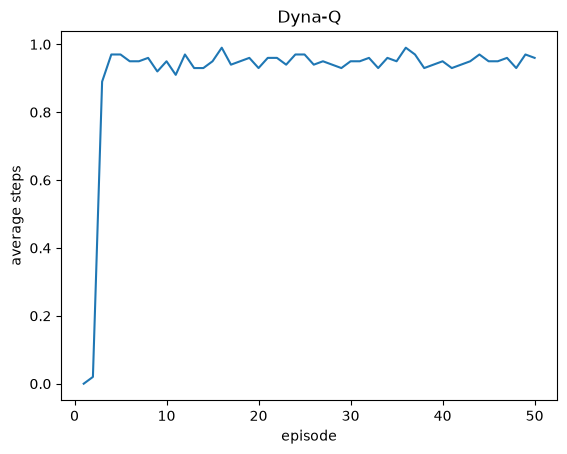

In [21]:
episodes    = 50
gamma       = 0.95
epsilon     = 0.01
alpha       = 1
experiments = 100
n           = 20

simulations = np.zeros((experiments, episodes), dtype=float)
pbar = tqdm(total=episodes * experiments)

for i in range(experiments):
    sims = simulate_dyna_Q_sim(
        AI="scrooge",
        gamma=gamma,
        eps=epsilon,
        alpha=alpha,
        n=n,
        n_episodes=episodes,
        seed=episodes * i,
        pbar=pbar,
    )
    simulations[i] = sims

pbar.close()

average_wins = np.mean(simulations, axis=0)

# Your existing plot helper. (The version in your prompt called plot_dyna_Q_steps
# with `wins=average_moves`, but the variable was named average_wins — typo.)
plot_dyna_Q_steps(steps=average_wins, title="Dyna-Q")